# Milestone 3 — interpretability, extra models, walk-forward, robustness

Same 55-feature pipeline as notebook 02. Threshold robustness, Model E bake-off, SHAP via xgboost pred_contribs, expanding walk-forward, and Model G on stress_any.shift(-5).


## Setup and shared M2 pipeline


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    precision_recall_curve, roc_curve,
)
from xgboost import XGBClassifier
import xgboost as xgb
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
np.random.seed(42)
HERE = Path.cwd()
REPO_ROOT = HERE if (HERE / "src" / "macro_stress").exists() else HERE.parent
DATA_PATH = REPO_ROOT / "data" / "Global_Market_Stress_and_Liquidity_Regimes.csv"
FIG_DIR = REPO_ROOT / "figures" / "notebook"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.is_file():
    raise SystemExit("Put the Kaggle CSV at data/Global_Market_Stress_and_Liquidity_Regimes.csv")
TEST_SIZE = 0.2
LAGS = [1, 3, 5]
N_BOOT = 2000
print("Environment ready.")


Environment ready.


In [2]:
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df["gold_ret"] = np.log(df["Gold"]).diff()
df["spy_ret"] = np.log(df["Equities_US"]).diff()
df["btc_ret"] = np.log(df["Crypto_Bitcoin"]).diff()
df["Gold_Rolling_Vol_30d"] = df["gold_ret"].rolling(30).std() * np.sqrt(252)
print("Shape:", df.shape, "  Dates:", df["Date"].min().date(), "->", df["Date"].max().date())

def regime_from_quantile(s, q=0.66):
    thr = s.quantile(q)
    return (s >= thr).astype(int), thr
df["stress_hys"], _ = regime_from_quantile(df["High_Yield_Spread"])
df["stress_fsi"], _ = regime_from_quantile(df["Financial_Stress_Index"])
df["stress_vix"], _ = regime_from_quantile(df["Volatility_Index"])
df["stress_any"] = ((df["stress_hys"] + df["stress_fsi"] + df["stress_vix"]) >= 1).astype(int)
df["stress_all"] = ((df["stress_hys"] + df["stress_fsi"] + df["stress_vix"]) == 3).astype(int)
MACRO_LEVELS = ["Volatility_Index", "Yield_Curve_Spread", "High_Yield_Spread",
                "Financial_Stress_Index", "SPY_Drawdown", "Stock_Bond_Corr_90d",
                "SPY_RSI_14", "GLD_RSI_14"]
VOL_LEVELS = ["SPY_Rolling_Vol_30d", "BTC_Rolling_Vol_30d", "Gold_Rolling_Vol_30d"]
RET_COLS = ["gold_ret", "spy_ret", "btc_ret"]
feat = pd.DataFrame(index=df.index)
feat["Date"] = df["Date"]
for c in MACRO_LEVELS + VOL_LEVELS:
    feat[c] = df[c]
    for L in LAGS:
        feat[f"{c}_lag{L}"] = df[c].shift(L)
for c in RET_COLS:
    for L in LAGS:
        feat[f"{c}_lag{L}"] = df[c].shift(L)
feat["stress_hys_t"] = df["stress_hys"]
feat["stress_any_t"] = df["stress_any"]
for col in RET_COLS:
    feat[col] = df[col]
feat["stress_hys"] = df["stress_hys"]
feat["stress_any"] = df["stress_any"]
EXCLUDE = ["Date"] + RET_COLS + ["stress_hys", "stress_any"]
FEATURE_COLS = [c for c in feat.columns if c not in EXCLUDE]
print(f"Feature matrix: {feat.shape}, predictors: {len(FEATURE_COLS)}")
assert len(FEATURE_COLS) == 55

def chrono_split(data, feature_cols, target, test_size=TEST_SIZE):
    aligned = data.loc[target.dropna().index].copy()
    aligned = aligned.dropna(subset=feature_cols)
    y = target.loc[aligned.index]
    n_test = max(1, int(len(aligned) * test_size))
    split_idx = len(aligned) - n_test
    return (aligned.iloc[:split_idx][feature_cols].values,
            aligned.iloc[split_idx:][feature_cols].values,
            y.iloc[:split_idx].values, y.iloc[split_idx:].values,
            aligned.iloc[:split_idx]["Date"].values,
            aligned.iloc[split_idx:]["Date"].values)

target_E = (df["gold_ret"].shift(-1) > df["spy_ret"].shift(-1)).astype(float)
target_E[df["gold_ret"].shift(-1).isna() | df["spy_ret"].shift(-1).isna()] = np.nan
target_G = df["stress_any"].shift(-5)
print("Targets ready: Model E (gold>spy tomorrow), Model G (stress_any in 5 days).")


Shape: (4150, 22)   Dates: 2014-10-17 -> 2026-02-25
Feature matrix: (4150, 61), predictors: 55
Targets ready: Model E (gold>spy tomorrow), Model G (stress_any in 5 days).


## Threshold robustness q=0.66 / 0.75 / 0.90


,threshold_q,regime,n_high,n_low,widening_hi_minus_lo,CI_lo,CI_hi,CI_excludes_zero
0,0.66,stress_hys,1418,2732,0.00038,-0.00044,0.00120,False
1,0.66,stress_fsi,1414,2736,-0.00012,-0.00095,0.00078,False
2,0.66,stress_vix,1412,2738,0.00247,0.00158,0.00343,True
3,0.66,stress_any,2337,1813,0.00096,0.00024,0.00166,True
4,0.75,stress_hys,1039,3111,0.00002,-0.00094,0.00101,False
5,0.75,stress_fsi,1043,3107,-0.00008,-0.00114,0.00101,False
6,0.75,stress_vix,1039,3111,0.00227,0.00117,0.00339,True
7,0.75,stress_any,1701,2449,0.00095,0.00014,0.00177,True
8,0.90,stress_hys,415,3735,0.00058,-0.00129,0.00240,False
9,0.90,stress_fsi,420,3730,-0.00000,-0.00187,0.00192,False


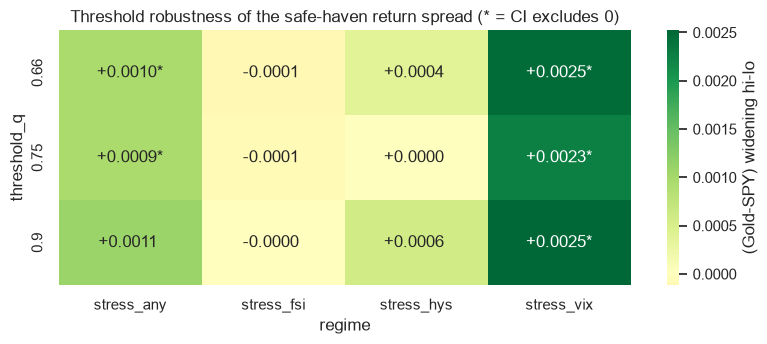

Cells with CI excluding zero: 5 / 12


In [3]:
THRESHOLDS = [0.66, 0.75, 0.90]
REGIME_SOURCE = {"stress_hys": "High_Yield_Spread", "stress_fsi": "Financial_Stress_Index",
                 "stress_vix": "Volatility_Index"}
def build_regime_at(q):
    out = {}
    for name, src in REGIME_SOURCE.items():
        out[name] = (df[src] >= df[src].quantile(q)).astype(int).values
    out["stress_any"] = ((out["stress_hys"] + out["stress_fsi"] + out["stress_vix"]) >= 1).astype(int)
    return out
def bootstrap_diff_ci(d_hi, d_lo, n_boot=N_BOOT, alpha=0.05, seed=0):
    rng = np.random.default_rng(seed)
    a = np.asarray(pd.Series(d_hi).dropna()); b = np.asarray(pd.Series(d_lo).dropna())
    if len(a) < 5 or len(b) < 5:
        return float("nan"), float("nan"), float("nan")
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        diffs[i] = rng.choice(a, size=len(a), replace=True).mean() - rng.choice(b, size=len(b), replace=True).mean()
    lo, hi = np.quantile(diffs, [alpha / 2, 1 - alpha / 2])
    return float(a.mean() - b.mean()), float(lo), float(hi)
spread = (df["gold_ret"] - df["spy_ret"])
rows = []
for q in THRESHOLDS:
    R = build_regime_at(q)
    for reg in ["stress_hys", "stress_fsi", "stress_vix", "stress_any"]:
        mask = R[reg]
        m, lo, hi = bootstrap_diff_ci(spread[mask == 1], spread[mask == 0], seed=int(q * 1000))
        rows.append({"threshold_q": q, "regime": reg, "n_high": int(mask.sum()),
                     "n_low": int((1 - mask).sum()), "widening_hi_minus_lo": m,
                     "CI_lo": lo, "CI_hi": hi, "CI_excludes_zero": (lo > 0) or (hi < 0)})
threshold_robustness = pd.DataFrame(rows)
display(threshold_robustness.round(5))
heat_widen = threshold_robustness.pivot(index="threshold_q", columns="regime", values="widening_hi_minus_lo")
heat_excl = threshold_robustness.pivot(index="threshold_q", columns="regime", values="CI_excludes_zero")
annot = heat_widen.copy().astype(str)
for i in heat_widen.index:
    for j in heat_widen.columns:
        annot.loc[i, j] = f"{heat_widen.loc[i, j]:+.4f}" + ("*" if bool(heat_excl.loc[i, j]) else " ")
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(heat_widen, annot=annot.values, fmt="", cmap="RdYlGn", center=0.0, ax=ax,
            cbar_kws={"label": "(Gold-SPY) widening hi-lo"})
ax.set_title("Threshold robustness of the safe-haven return spread (* = CI excludes 0)")
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_threshold_heatmap.png", dpi=140, bbox_inches="tight"); plt.show()
print("Cells with CI excluding zero:", int(threshold_robustness["CI_excludes_zero"].sum()), "/", len(threshold_robustness))


## Model E bake-off


In [4]:
X_tr_E, X_te_E, y_tr_E, y_te_E, d_tr_E, d_te_E = chrono_split(feat, FEATURE_COLS, target_E)
y_tr_E = y_tr_E.astype(int); y_te_E = y_te_E.astype(int)
print("Train:", len(y_tr_E), pd.Timestamp(d_tr_E[0]).date(), "->", pd.Timestamp(d_tr_E[-1]).date())
print("Test :", len(y_te_E), pd.Timestamp(d_te_E[0]).date(), "->", pd.Timestamp(d_te_E[-1]).date())
print("Test Gold>SPY:", round(float(y_te_E.mean()), 3))

def model_E_metrics(name, y_true, y_pred, y_prob):
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred),
            "balanced": balanced_accuracy_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "brier": brier_score_loss(y_true, y_prob),
            "log_loss": log_loss(y_true, np.clip(y_prob, 1e-6, 1 - 1e-6))}

def fit_predict_proba(model, X_tr, y_tr, X_te):
    model.fit(X_tr, y_tr)
    prob = model.predict_proba(X_te)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return model, pred, prob

model_factories = {
    "Logistic (balanced)": lambda: Pipeline([("sc", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))]),
    "XGBoost": lambda: XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9, eval_metric="logloss", random_state=42, n_jobs=-1, verbosity=0),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=500, max_depth=8, min_samples_leaf=10,
        class_weight="balanced", n_jobs=-1, random_state=42),
    "MLP (2x64)": lambda: Pipeline([("sc", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=(64, 64), activation="relu", solver="adam",
                              alpha=1e-3, max_iter=400, random_state=42))]),
}
try:
    from lightgbm import LGBMClassifier
    model_factories["LightGBM"] = lambda: LGBMClassifier(n_estimators=500, num_leaves=31, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9, class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1)
except ImportError:
    print("LightGBM not installed; skipping.")
try:
    from catboost import CatBoostClassifier
    model_factories["CatBoost"] = lambda: CatBoostClassifier(iterations=500, depth=5, learning_rate=0.05,
        loss_function="Logloss", auto_class_weights="Balanced", random_seed=42, verbose=False)
except ImportError:
    print("CatBoost not installed; skipping.")
fitted_models = {}; results_E = []
for name, factory in model_factories.items():
    mdl, pred, prob = fit_predict_proba(factory(), X_tr_E, y_tr_E, X_te_E)
    fitted_models[name] = mdl
    results_E.append(model_E_metrics(name, y_te_E, pred, prob))
    print("fitted", name)


Train: 3292 2014-11-21 -> 2023-11-25
Test : 822 2023-11-26 -> 2026-02-24
Test Gold>SPY: 0.383


fitted Logistic (balanced)


fitted XGBoost


fitted RandomForest


fitted MLP (2x64)


fitted LightGBM


fitted CatBoost


,accuracy,balanced,f1,roc_auc,brier,log_loss
model,,,,,,
Stacking (xgb+lgb+logit),0.6131,0.5079,0.1017,0.6785,0.2209,0.6311
XGBoost,0.6436,0.5932,0.4482,0.6773,0.2216,0.6319
CatBoost,0.6399,0.6179,0.5272,0.6722,0.2219,0.6297
LightGBM,0.6363,0.5993,0.4818,0.6687,0.2387,0.6835
RandomForest,0.6423,0.6644,0.6192,0.6655,0.2289,0.6501
Logistic (balanced),0.5766,0.5883,0.5360,0.6091,0.2459,0.6945
MLP (2x64),0.5292,0.5450,0.4994,0.5673,0.4377,3.6077


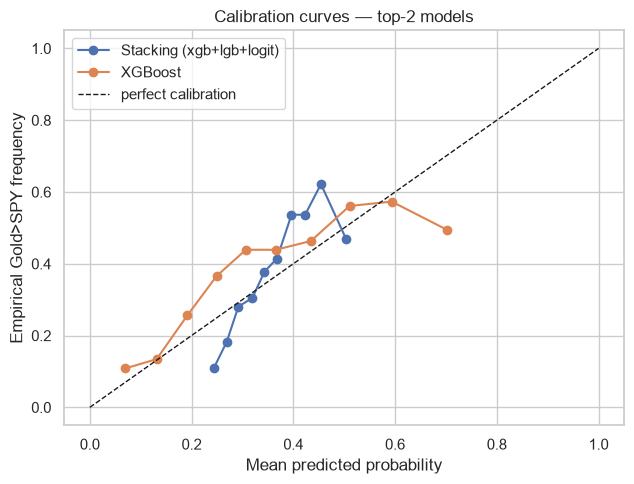

Best Model E by ROC-AUC: Stacking (xgb+lgb+logit) 0.6785


In [5]:
def make_stacking():
    from lightgbm import LGBMClassifier
    estimators = [
        ("xgb", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                              subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                              random_state=42, n_jobs=-1, verbosity=0)),
        ("lgb", LGBMClassifier(n_estimators=300, num_leaves=31, learning_rate=0.05,
                               class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1)),
        ("logit", Pipeline([("sc", StandardScaler()),
                            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))])),
    ]
    return StackingClassifier(estimators=estimators,
                              final_estimator=LogisticRegression(max_iter=2000, random_state=42),
                              cv=5, stack_method="predict_proba", n_jobs=-1, passthrough=False)
try:
    stack, pred_st, prob_st = fit_predict_proba(make_stacking(), X_tr_E, y_tr_E, X_te_E)
    fitted_models["Stacking (xgb+lgb+logit)"] = stack
    results_E.append(model_E_metrics("Stacking (xgb+lgb+logit)", y_te_E, pred_st, prob_st))
except Exception as exc:
    print("Stacking skipped:", type(exc).__name__, exc)
res_E = pd.DataFrame(results_E).set_index("model").round(4).sort_values("roc_auc", ascending=False)
display(res_E)
top2 = res_E.head(2).index.tolist()
fig, ax = plt.subplots(figsize=(6.5, 5))
for name in top2:
    mdl = fitted_models[name]
    prob = mdl.predict_proba(X_te_E)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_te_E, prob, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Empirical Gold>SPY frequency")
ax.set_title("Calibration curves — top-2 models"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_calibration.png", dpi=140, bbox_inches="tight"); plt.show()
print("Best Model E by ROC-AUC:", res_E.index[0], float(res_E.iloc[0]["roc_auc"]))


## SHAP for Model E (xgboost pred_contribs=True)


SHAP values shape: (822, 55) expected value: -0.7021


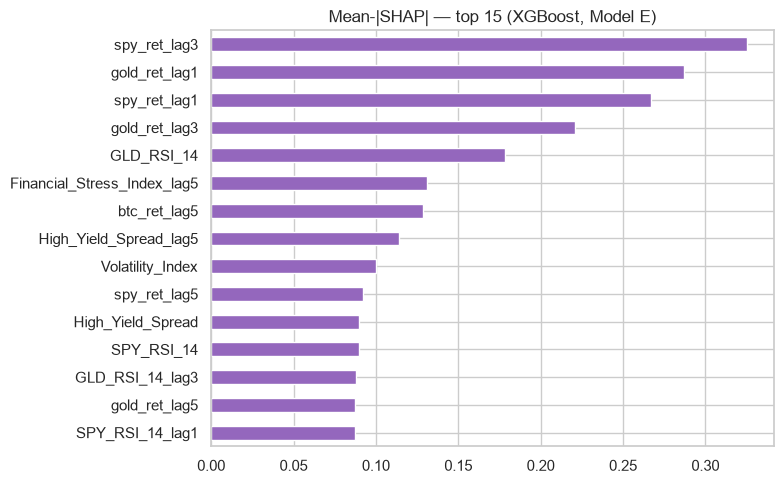

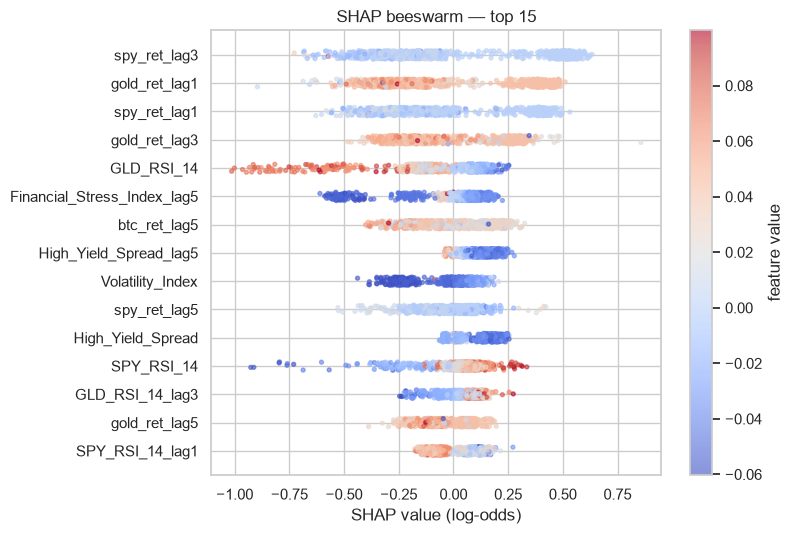

In [6]:
shap_model = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
    random_state=42, n_jobs=-1, verbosity=0).fit(X_tr_E, y_tr_E)
X_te_df = pd.DataFrame(X_te_E, columns=FEATURE_COLS)
_booster = shap_model.get_booster()
_contribs = _booster.predict(xgb.DMatrix(X_te_df.values, feature_names=FEATURE_COLS), pred_contribs=True)
shap_values_E = _contribs[:, :-1]
expected_value_E = float(_contribs[:, -1].mean())
print("SHAP values shape:", shap_values_E.shape, "expected value:", round(expected_value_E, 4))
mean_abs = pd.Series(np.abs(shap_values_E).mean(axis=0), index=FEATURE_COLS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
mean_abs.head(15).iloc[::-1].plot.barh(ax=ax, color="tab:purple")
ax.set_title("Mean-|SHAP| — top 15 (XGBoost, Model E)")
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_shap_bar.png", dpi=140, bbox_inches="tight"); plt.show()
order = mean_abs.head(15).index
fig, ax = plt.subplots(figsize=(8, 5.5))
for i, ft in enumerate(order[::-1]):
    vals = shap_values_E[:, FEATURE_COLS.index(ft)]
    feat_vals = X_te_df[ft].to_numpy()
    sc = ax.scatter(vals, np.full(len(vals), i) + np.random.uniform(-0.15, 0.15, len(vals)),
                    c=feat_vals, cmap="coolwarm", s=8, alpha=0.6)
ax.set_yticks(range(15), list(order[::-1]))
ax.set_xlabel("SHAP value (log-odds)")
ax.set_title("SHAP beeswarm — top 15")
plt.colorbar(sc, ax=ax, label="feature value")
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_shap_beeswarm.png", dpi=140, bbox_inches="tight"); plt.show()


,gain_imp,rank_gain_imp,mean_abs_shap,rank_mean_abs_shap,perm_drop_AUC,rank_perm_drop_AUC
spy_ret_lag3,0.0339,1,0.3254,1,0.0462,2
gold_ret_lag1,0.0280,3,0.2872,2,0.0429,3
spy_ret_lag1,0.0322,2,0.2671,3,0.0534,1
gold_ret_lag3,0.0259,4,0.2208,4,0.0267,4
GLD_RSI_14,0.0175,32,0.1786,5,-0.0016,51
Financial_Stress_Index_lag5,0.0163,44,0.1308,6,-0.0041,54
btc_ret_lag5,0.0173,35,0.1287,7,0.0074,5
High_Yield_Spread_lag5,0.0166,42,0.1140,8,0.0021,11
Volatility_Index,0.0190,13,0.1001,9,0.0028,7
spy_ret_lag5,0.0182,22,0.0923,10,0.0011,18


gain vs SHAP 0.1891774891774892
gain vs perm 0.3657287157287158
SHAP vs perm 0.36746031746031754
Dependence top-4: ['spy_ret_lag3', 'gold_ret_lag1', 'spy_ret_lag1', 'gold_ret_lag3']


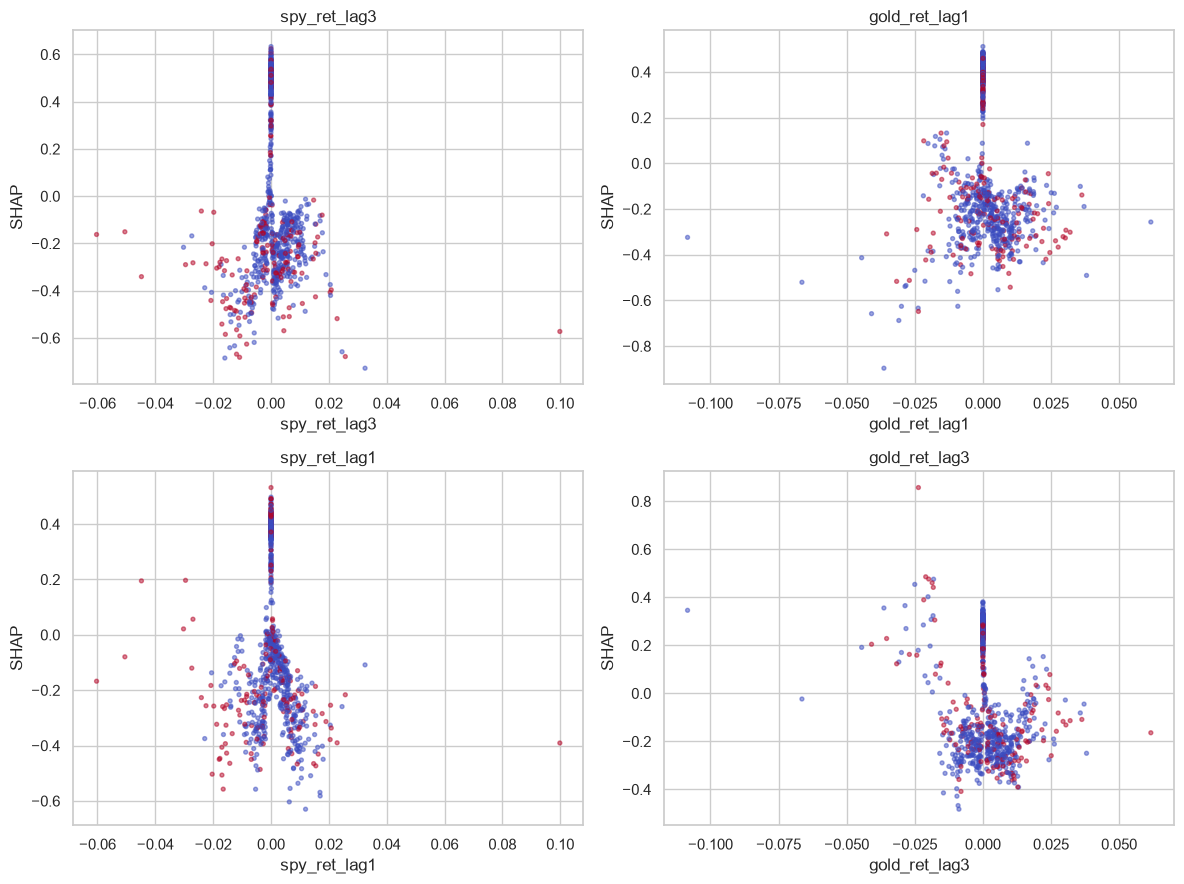

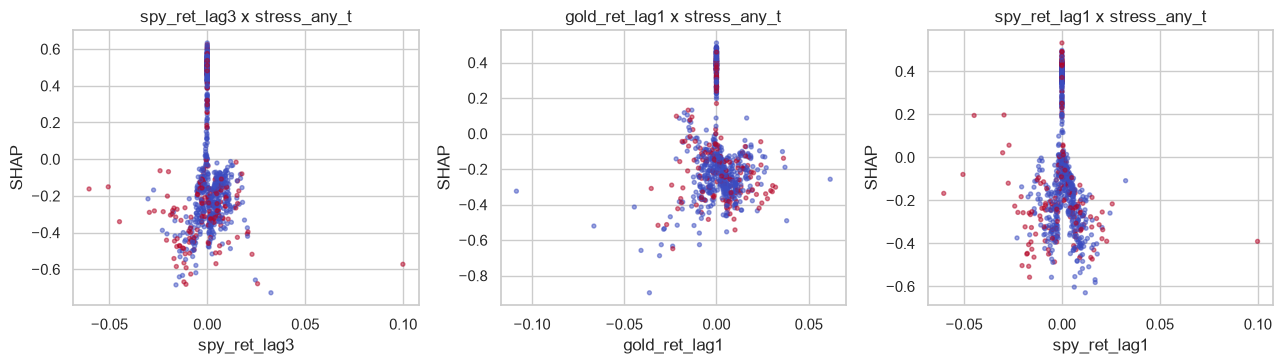

In [7]:
gain_imp = pd.Series(shap_model.feature_importances_, index=FEATURE_COLS, name="gain_imp")
shap_imp = pd.Series(np.abs(shap_values_E).mean(axis=0), index=FEATURE_COLS, name="mean_abs_shap")
perm = permutation_importance(shap_model, X_te_df.values, y_te_E, n_repeats=10,
                              random_state=42, scoring="roc_auc", n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURE_COLS, name="perm_drop_AUC")
importance_table = pd.concat([gain_imp, shap_imp, perm_imp], axis=1)
for col in importance_table.columns:
    importance_table[f"rank_{col}"] = importance_table[col].rank(ascending=False).astype(int)
top_by_shap = importance_table.sort_values("mean_abs_shap", ascending=False).head(15)
display(top_by_shap[["gain_imp", "rank_gain_imp", "mean_abs_shap", "rank_mean_abs_shap",
                     "perm_drop_AUC", "rank_perm_drop_AUC"]].round(4))
ranks = importance_table[["rank_gain_imp", "rank_mean_abs_shap", "rank_perm_drop_AUC"]]
print("gain vs SHAP", stats.spearmanr(ranks["rank_gain_imp"], ranks["rank_mean_abs_shap"]).statistic)
print("gain vs perm", stats.spearmanr(ranks["rank_gain_imp"], ranks["rank_perm_drop_AUC"]).statistic)
print("SHAP vs perm", stats.spearmanr(ranks["rank_mean_abs_shap"], ranks["rank_perm_drop_AUC"]).statistic)
top4 = shap_imp.sort_values(ascending=False).head(4).index.tolist()
print("Dependence top-4:", top4)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, ft in zip(axes.flatten(), top4):
    ax.scatter(X_te_df[ft], shap_values_E[:, FEATURE_COLS.index(ft)], s=8, alpha=0.5,
               c=X_te_df["stress_any_t"], cmap="coolwarm")
    ax.set_xlabel(ft); ax.set_ylabel("SHAP"); ax.set_title(ft)
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_shap_dependence.png", dpi=140, bbox_inches="tight"); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, partner in zip(axes, [f for f in top4 if f != "stress_any_t"][:3]):
    ax.scatter(X_te_df[partner], shap_values_E[:, FEATURE_COLS.index(partner)],
               c=X_te_df["stress_any_t"], cmap="coolwarm", s=8, alpha=0.5)
    ax.set_title(f"{partner} x stress_any_t"); ax.set_xlabel(partner); ax.set_ylabel("SHAP")
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_shap_interaction.png", dpi=140, bbox_inches="tight"); plt.show()


COVID crash (Mar 2020): closest 2020-03-16 (TRAIN) idx=1942
Inflation / rates (Jun 2022): closest 2022-06-13 (TRAIN) idx=2761
Banking stress (Mar 2023): closest 2023-03-13 (TRAIN) idx=3034
Calm OOS day (Jul 2024): closest 2024-07-15 (TEST) idx=3524


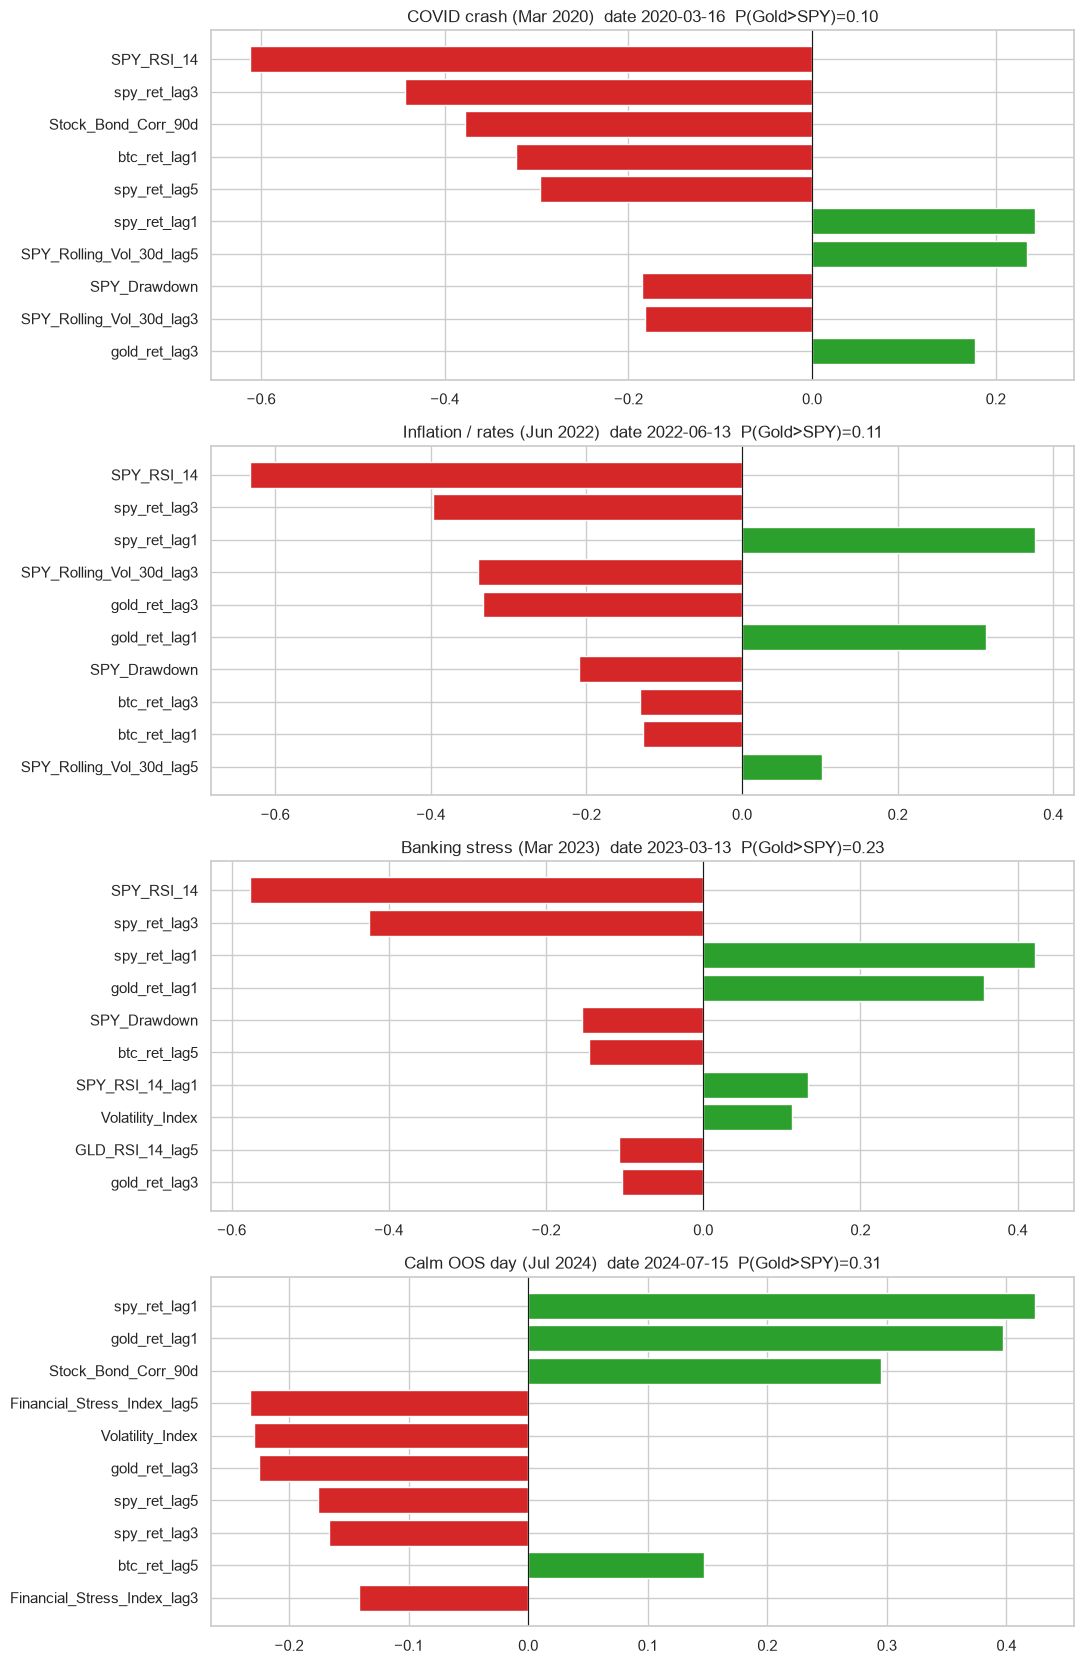

In [8]:
_full_aligned = feat.dropna(subset=FEATURE_COLS).reset_index(drop=True)
_full_dates = pd.to_datetime(_full_aligned["Date"])
_full_X = _full_aligned[FEATURE_COLS].values
_full_contribs = _booster.predict(xgb.DMatrix(_full_X, feature_names=FEATURE_COLS), pred_contribs=True)
shap_values_full = _full_contribs[:, :-1]
EVENT_DATES = {
    "COVID crash (Mar 2020)": "2020-03-16",
    "Inflation / rates (Jun 2022)": "2022-06-13",
    "Banking stress (Mar 2023)": "2023-03-13",
    "Calm OOS day (Jul 2024)": "2024-07-15",
}
def nearest_full_idx(target_date):
    deltas = np.abs((_full_dates - pd.Timestamp(target_date)).dt.days.values)
    return int(np.argmin(deltas))
usable_events = {}
for label, dt in EVENT_DATES.items():
    idx = nearest_full_idx(dt)
    actual = pd.Timestamp(_full_dates.iloc[idx]).date()
    usable_events[label] = idx
    region = "TEST" if pd.Timestamp(_full_dates.iloc[idx]) >= pd.Timestamp(d_te_E[0]) else "TRAIN"
    print(f"{label}: closest {actual} ({region}) idx={idx}")
fig, axes = plt.subplots(len(usable_events), 1, figsize=(11, 4.2 * len(usable_events)))
if len(usable_events) == 1:
    axes = [axes]
for ax, (label, idx) in zip(axes, usable_events.items()):
    sv = shap_values_full[idx]
    contribs = pd.Series(sv, index=FEATURE_COLS).sort_values(key=np.abs, ascending=True).tail(10)
    colors = ["#2ca02c" if v > 0 else "#d62728" for v in contribs.values]
    ax.barh(contribs.index, contribs.values, color=colors)
    ax.axvline(0, color="k", lw=0.8)
    margin = float(_full_contribs[idx, :].sum())
    prob_pos = 1.0 / (1.0 + np.exp(-margin))
    ax.set_title(f"{label}  date {pd.Timestamp(_full_dates.iloc[idx]).date()}  P(Gold>SPY)={prob_pos:.2f}")
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_shap_local.png", dpi=140, bbox_inches="tight"); plt.show()


## Expanding walk-forward, test years 2019-max


,n_train,n_test,pos_rate_test,roc_auc,bal_acc,brier
test_year,,,,,,
2019,1502,365,0.3096,0.6445,0.5087,0.2143
2020,1867,366,0.3634,0.6376,0.5274,0.2323
2021,2233,365,0.3260,0.6000,0.5564,0.2377
2022,2598,365,0.3589,0.6365,0.5428,0.2428
2023,2963,365,0.3123,0.6643,0.5970,0.2110
2024,3328,366,0.3716,0.6567,0.5541,0.2283
2025,3694,365,0.3836,0.6908,0.6094,0.2133
2026,4059,55,0.4727,0.7016,0.6061,0.2303


Mean ROC-AUC 0.654 std 0.0323


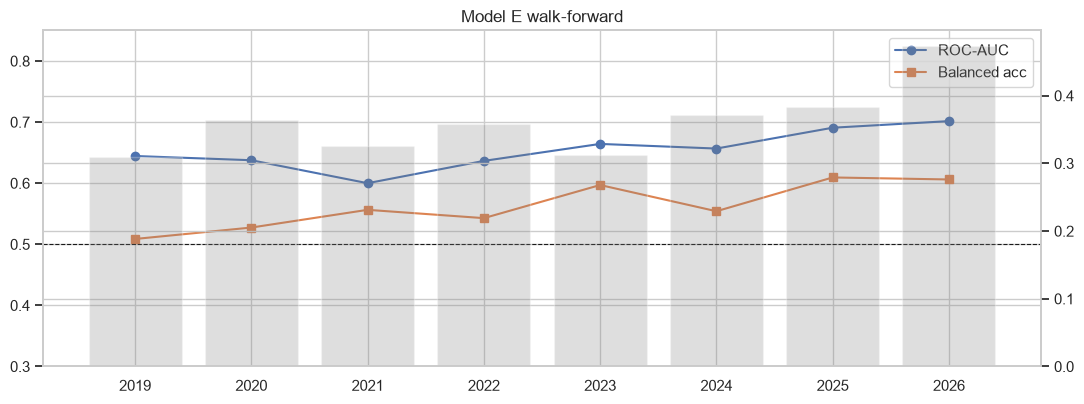

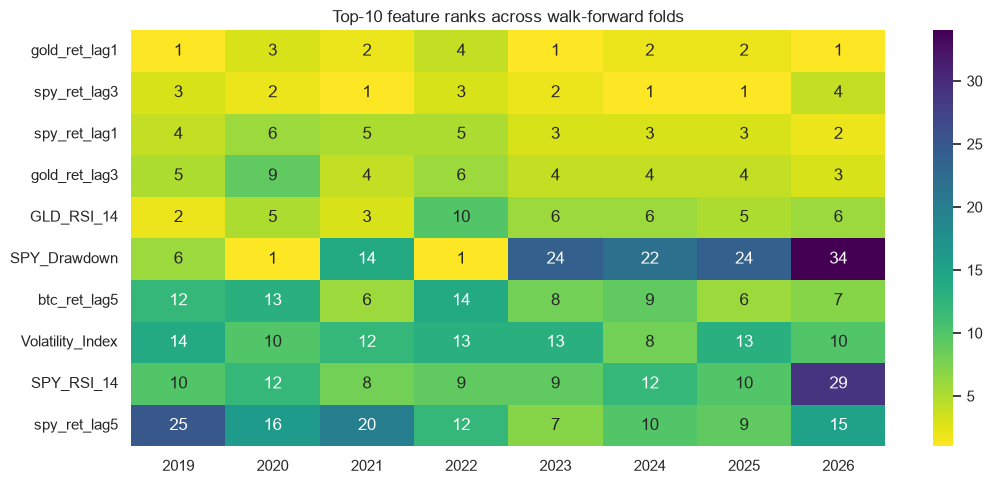

In [9]:
aligned_E = feat.loc[target_E.dropna().index].copy()
aligned_E = aligned_E.dropna(subset=FEATURE_COLS)
aligned_E["target_E"] = target_E.loc[aligned_E.index].astype(int)
aligned_E = aligned_E.reset_index(drop=True)
dates_E = pd.to_datetime(aligned_E["Date"])
WF_LAST_YEAR = int(dates_E.dt.year.max())
walk_rows = []; walk_shap_imps = {}
for test_year in range(2019, WF_LAST_YEAR + 1):
    tr_mask = dates_E.dt.year < test_year
    te_mask = dates_E.dt.year == test_year
    if te_mask.sum() < 30 or tr_mask.sum() < 200:
        continue
    X_tr_w = aligned_E.loc[tr_mask, FEATURE_COLS].values
    y_tr_w = aligned_E.loc[tr_mask, "target_E"].values
    X_te_w = aligned_E.loc[te_mask, FEATURE_COLS].values
    y_te_w = aligned_E.loc[te_mask, "target_E"].values
    mdl_w = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
                          subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                          random_state=42, n_jobs=-1, verbosity=0).fit(X_tr_w, y_tr_w)
    prob = mdl_w.predict_proba(X_te_w)[:, 1]
    pred = (prob >= 0.5).astype(int)
    walk_rows.append({"test_year": test_year, "n_train": int(tr_mask.sum()), "n_test": int(te_mask.sum()),
                      "pos_rate_test": float(y_te_w.mean()),
                      "roc_auc": roc_auc_score(y_te_w, prob),
                      "bal_acc": balanced_accuracy_score(y_te_w, pred),
                      "brier": brier_score_loss(y_te_w, prob)})
    contribs_w = mdl_w.get_booster().predict(xgb.DMatrix(X_te_w, feature_names=FEATURE_COLS), pred_contribs=True)
    walk_shap_imps[test_year] = pd.Series(np.abs(contribs_w[:, :-1]).mean(axis=0), index=FEATURE_COLS)
walk_df = pd.DataFrame(walk_rows).set_index("test_year").round(4)
display(walk_df)
print("Mean ROC-AUC", round(float(walk_df["roc_auc"].mean()), 4), "std", round(float(walk_df["roc_auc"].std()), 4))
fig, ax1 = plt.subplots(figsize=(11, 4.2))
ax1.plot(walk_df.index, walk_df["roc_auc"], "-o", label="ROC-AUC")
ax1.plot(walk_df.index, walk_df["bal_acc"], "-s", label="Balanced acc")
ax1.axhline(0.50, color="k", lw=0.8, ls="--")
ax1.set_ylim(0.30, 0.85)
ax2 = ax1.twinx()
ax2.bar(walk_df.index, walk_df["pos_rate_test"], color="tab:gray", alpha=0.25)
ax1.set_title("Model E walk-forward")
ax1.legend(loc="upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_walkforward.png", dpi=140, bbox_inches="tight"); plt.show()
shap_imp_panel = pd.DataFrame(walk_shap_imps)
shap_rank_panel = shap_imp_panel.rank(ascending=False)
mean_imp = shap_imp_panel.mean(axis=1).sort_values(ascending=False)
top10 = mean_imp.head(10).index.tolist()
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(shap_rank_panel.loc[top10], annot=True, fmt=".0f", cmap="viridis_r", ax=ax)
ax.set_title("Top-10 feature ranks across walk-forward folds")
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_walkforward_ranks.png", dpi=140, bbox_inches="tight"); plt.show()


## Model G on stress_any.shift(-5): imbalance handling, PR-AUC headline


Train pos rate 0.6439 Test pos rate 0.2433


SMOTE train size 4234 pos 0.5


Tuned F1 threshold on last 15% of train: 0.8669


,threshold,accuracy,balanced,f1,roc_auc,pr_auc
model,,,,,,
Majority,0.5000,0.2433,0.5000,0.3914,0.5000,0.2433
Regime persists,0.5000,0.8382,0.7761,0.6633,0.7761,0.5240
Logistic (balanced),0.5000,0.8236,0.7376,0.6113,0.8644,0.7095
XGBoost (default),0.5000,0.7798,0.7476,0.6022,0.8382,0.6316
XGBoost (scale_pos_weight=0.55),0.5000,0.7944,0.7522,0.6133,0.8439,0.6349
XGBoost + SMOTE,0.5000,0.7932,0.7463,0.6065,0.8555,0.6543
XGBoost (spw + threshold=0.867),0.8669,0.7871,0.6405,0.4479,0.8439,0.6349


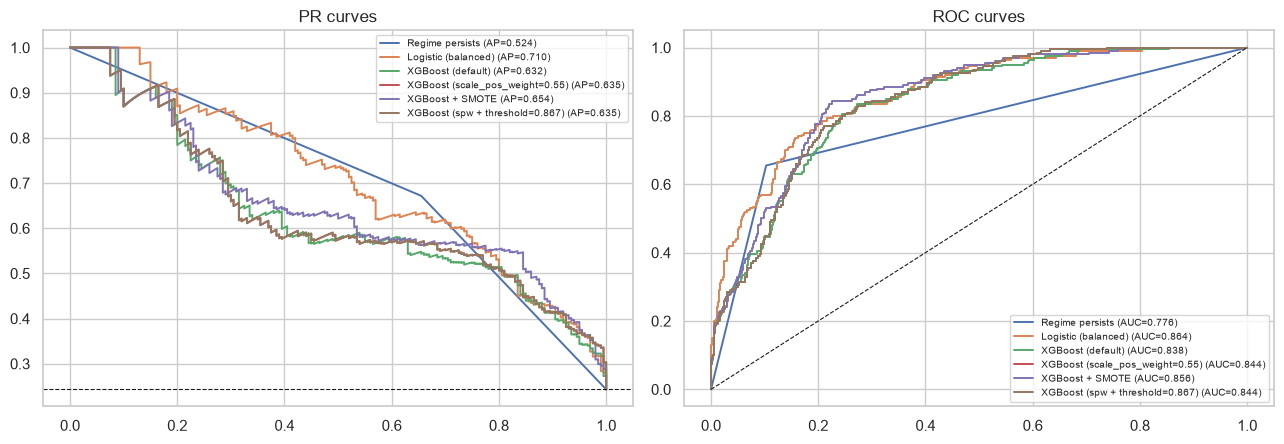

Best Model G by PR-AUC: Logistic (balanced) 0.7095


In [10]:
X_tr_G, X_te_G, y_tr_G, y_te_G, d_tr_G, d_te_G = chrono_split(feat, FEATURE_COLS, target_G)
y_tr_G = y_tr_G.astype(int); y_te_G = y_te_G.astype(int)
print("Train pos rate", round(float(y_tr_G.mean()), 4), "Test pos rate", round(float(y_te_G.mean()), 4))
n_val = max(150, int(0.15 * len(X_tr_G)))
X_tr_inner, y_tr_inner = X_tr_G[:-n_val], y_tr_G[:-n_val]
X_val, y_val = X_tr_G[-n_val:], y_tr_G[-n_val:]

def model_G_metrics(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {"model": name, "threshold": float(threshold),
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced": balanced_accuracy_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else float("nan"),
            "pr_auc": average_precision_score(y_true, y_prob)}

def best_f1_threshold(y_true, y_prob):
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    f1s = 2 * prec * rec / (prec + rec + 1e-12)
    best = int(np.nanargmax(f1s[:-1])) if len(f1s) > 1 else 0
    return float(thr[best]) if len(thr) > 0 else 0.5

variants = {}
variants["Majority"] = np.full_like(y_te_G, fill_value=int(pd.Series(y_tr_G).mode().iloc[0]), dtype=float)
persist_idx = FEATURE_COLS.index("stress_any_t")
variants["Regime persists"] = X_te_G[:, persist_idx].astype(float)
logit_g = Pipeline([("sc", StandardScaler()),
                    ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))]).fit(X_tr_G, y_tr_G)
variants["Logistic (balanced)"] = logit_g.predict_proba(X_te_G)[:, 1]
xgb_plain = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
                          colsample_bytree=0.9, eval_metric="logloss", random_state=42, n_jobs=-1, verbosity=0).fit(X_tr_G, y_tr_G)
variants["XGBoost (default)"] = xgb_plain.predict_proba(X_te_G)[:, 1]
neg, pos = (y_tr_G == 0).sum(), (y_tr_G == 1).sum()
spw = float(neg) / max(1, pos)
xgb_spw = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
                        colsample_bytree=0.9, eval_metric="logloss", scale_pos_weight=spw,
                        random_state=42, n_jobs=-1, verbosity=0).fit(X_tr_G, y_tr_G)
variants[f"XGBoost (scale_pos_weight={spw:.2f})"] = xgb_spw.predict_proba(X_te_G)[:, 1]
try:
    from imblearn.over_sampling import SMOTE
    smote = SMOTE(random_state=42, k_neighbors=min(5, max(1, pos - 1)))
    X_sm, y_sm = smote.fit_resample(X_tr_G, y_tr_G)
    xgb_sm = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
                           colsample_bytree=0.9, eval_metric="logloss", random_state=42, n_jobs=-1, verbosity=0).fit(X_sm, y_sm)
    variants["XGBoost + SMOTE"] = xgb_sm.predict_proba(X_te_G)[:, 1]
    print("SMOTE train size", len(y_sm), "pos", round(float(y_sm.mean()), 3))
except Exception as exc:
    print("SMOTE skipped:", type(exc).__name__, exc)
xgb_inner = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
                          colsample_bytree=0.9, eval_metric="logloss", scale_pos_weight=spw,
                          random_state=42, n_jobs=-1, verbosity=0).fit(X_tr_inner, y_tr_inner)
tuned_thr = best_f1_threshold(y_val, xgb_inner.predict_proba(X_val)[:, 1])
print("Tuned F1 threshold on last 15% of train:", round(tuned_thr, 4))
xgb_thr_full = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
                             colsample_bytree=0.9, eval_metric="logloss", scale_pos_weight=spw,
                             random_state=42, n_jobs=-1, verbosity=0).fit(X_tr_G, y_tr_G)
variants[f"XGBoost (spw + threshold={tuned_thr:.3f})"] = xgb_thr_full.predict_proba(X_te_G)[:, 1]
rows_G = []
for name, prob in variants.items():
    thr = tuned_thr if "threshold=" in name else 0.5
    rows_G.append(model_G_metrics(name, y_te_G, prob, threshold=thr))
res_G = pd.DataFrame(rows_G).set_index("model").round(4)
display(res_G)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
base_rate = y_te_G.mean()
for name, prob in variants.items():
    if name == "Majority":
        continue
    p, r, _ = precision_recall_curve(y_te_G, prob)
    axes[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_te_G, prob):.3f})", lw=1.4)
    fpr, tpr, _ = roc_curve(y_te_G, prob)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te_G, prob):.3f})", lw=1.4)
axes[0].axhline(base_rate, color="k", lw=0.8, ls="--"); axes[0].set_title("PR curves"); axes[0].legend(fontsize=7)
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set_title("ROC curves"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "m3_modelG_pr_roc.png", dpi=140, bbox_inches="tight"); plt.show()
print("Best Model G by PR-AUC:", res_G["pr_auc"].idxmax(), float(res_G["pr_auc"].max()))


## Takeaway

VIX-based Gold-SPY widening is the robust regime result. XGBoost remains the Model E ranking leader; Random Forest wins balanced metrics. SHAP is dominated by lagged cross-asset returns. Walk-forward stays above 0.55 ROC-AUC. For Model G, PR-AUC (not accuracy) is the honest metric, and class-balanced logistic is hard to beat.
